In [ ]:
##########################################  Actividad 5 - Predicción de riesgo cardiovascular   #########################################

#################################################  Importar librerías, reproducibilidad  ################################################

# Instalar MLflow si no está disponible
try:
    import mlflow
except ModuleNotFoundError:
    !pip install -q mlflow
    import mlflow

    %pip install -q "mlflow==3.17.1"

# Importar librerías
import os, json, hashlib, platform, tempfile, warnings
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
import mlflow
import mlflow.sklearn
from mlflow.tracking import MlflowClient
from IPython.display import display


# Fijar semilla de reproducibilidad
SEED = 42
np.random.seed(SEED)


# Registro de versiones
OUT = Path('Actividad5_resultados')
OUT.mkdir(exist_ok=True)
versions = {k:version(k) for k in ['numpy','pandas','scipy','scikit-learn','matplotlib','seaborn','mlflow']}
(OUT/'dependencias.json').write_text(json.dumps({'python':platform.python_version(), **versions}, indent=2), encoding='utf-8')


print('Semilla:',SEED,'| Versiones:',versions)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 5.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 95.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 117.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 95.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 28.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 16.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 25.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
#######################################################  Configuración de MLflow  #######################################################

import mlflow
from pathlib import Path

# Base de datos local para registrar experimentos
TRACKING_DB = (Path.cwd() / "mlflow.db").resolve()
TRACKING_URI = f"sqlite:///{TRACKING_DB.as_posix()}"

# Configurar MLflow
mlflow.set_tracking_uri(TRACKING_URI)

# Nombre del experimento
EXPERIMENT_NAME = "Breast cancer clasification"
mlflow.set_experiment(EXPERIMENT_NAME)

print("MLflow configurado correctamente")
print("Tracking URI:", mlflow.get_tracking_uri())
print("Experimento:", EXPERIMENT_NAME)


2026/10/16 07:14:54 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/16 07:14:55 INFO mlflow.store.db.utils: Updating database tables
2026/10/16 07:14:59 INFO mlflow.tracking.fluent: Experiment with name 'Breast cancer clasification' does not exist. Creating a new experiment.


MLflow configurado correctamente
Tracking URI: sqlite:////content/mlflow.db
Experimento: Breast cancer clasification


Dataset: sklearn.datasets.load_breast_cancer
Duplicados eliminados:  0 | Valores negativos invalidados:  0
Nulos por variable (solo >0):
Series([], dtype: int64)
Distribución de clases: {0: 357, 1: 212}
SHA256 versión CLEANED: 349e0b6355d9acc2cc25d910999fb906288861f9fb19af75718fb8c444df036c


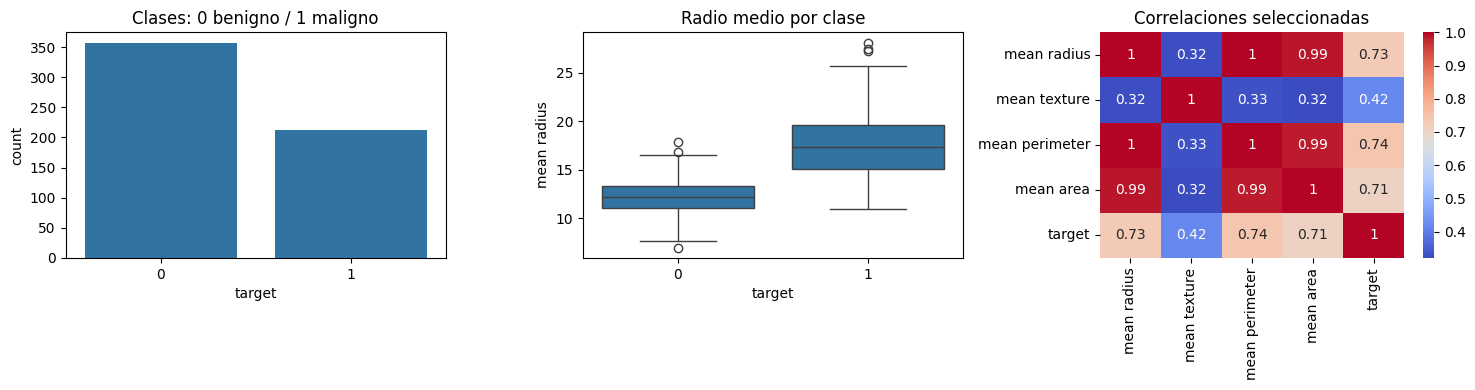

Entrenamiento: 455 | Prueba: 114 | Hash: 349e0b6355d9acc2


In [ ]:
##############################################  Carga de dataset y estandarización de datos  ############################################

# Carga dataset
data_original = load_breast_cancer(as_frame=True)
df_raw = data_original.frame.copy()
path_raw = OUT/'dataset_raw.csv'
df_raw.to_csv(path_raw,index=False)

# Elimina duplicados
df = df_raw.drop_duplicates().copy()
duplicados = len(df_raw)-len(df)

# Estandarización de datos
df['target'] = 1-df['target'].astype(int)
feature_cols = [c for c in df.columns if c!='target']
df[feature_cols] = df[feature_cols].apply(pd.to_numeric,errors='coerce')
negativos = int((df[feature_cols]<0).sum().sum())
df[feature_cols] = df[feature_cols].mask(df[feature_cols]<0)
clean_path = OUT/'dataset_cleaned.csv'
df.to_csv(clean_path,index=False)
dataset_hash=hashlib.sha256(clean_path.read_bytes()).hexdigest()

print('Dataset: sklearn.datasets.load_breast_cancer')
print('Duplicados eliminados: ',duplicados,'| Valores negativos invalidados: ',negativos)
print('Nulos por variable (solo >0):'); print(df.isna().sum()[lambda s:s>0])
print('Distribución de clases:',df.target.value_counts().sort_index().to_dict())
print('SHA256 versión CLEANED:',dataset_hash)


# Diccionario y metadatos de origen
(OUT/'diccionario_datos.txt').write_text(data_original.DESCR,encoding='utf-8')
(OUT/'CHANGELOG.md').write_text("""# CHANGELOG\n\n## v1.1 - Preparación reproducible\n- Fuente: sklearn.datasets.load_breast_cancer.\n- Eliminación de filas duplicadas.\n- Negativos en mediciones: NaN; ceros legítimos conservados.\n- Imputación y escalado solo dentro del pipeline entrenado.\n- RAW y CLEANED exportados con hash SHA256.\n""",encoding='utf-8')
fig,axs = plt.subplots(1,3,figsize=(15,4))
sns.countplot(data=df,x='target',ax=axs[0]);axs[0].set_title('Clases: 0 benigno / 1 maligno')
sns.boxplot(data=df,x='target',y='mean radius',ax=axs[1])
axs[1].set_title('Radio medio por clase')
sns.heatmap(df[['mean radius','mean texture','mean perimeter','mean area','target']].corr(),annot=True,cmap='coolwarm',ax=axs[2])
axs[2].set_title('Correlaciones seleccionadas')
plt.tight_layout()
fig.savefig(OUT/'eda.png',dpi=160)
plt.show()


# Configuración de pipelines de modelado
X = df[feature_cols].copy();
y = df['target'].copy()

# Partición estratificada (80/20)
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=.2,random_state=SEED,stratify=y)
num_cols = X.columns.tolist()
preprocessor = ColumnTransformer([('num',Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler())]),num_cols)])
cv_strategy = StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
print('Entrenamiento:',len(X_train),'| Prueba:',len(X_test),'| Hash:',dataset_hash[:16])

In [ ]:
####################################################  Evaluación y registro en MLflow  ###################################################

def evaluar_y_registrar_modelo(nombre_modelo, gs, X_train, y_train, X_test, y_test):
    with mlflow.start_run(run_name=nombre_modelo) as run:
        mlflow.set_tags({'dataset_sha256':dataset_hash,'target_positive':'maligno','seed':str(SEED),'dataset_source':'sklearn.load_breast_cancer'})
        mlflow.log_params({'seed':SEED,'cv_folds':cv_strategy.n_splits,'test_size':.2,'optimization_metric':'f1'})

        # 1. Entrenamiento del GridSearch
        gs.fit(X_train,y_train)
        best = gs.best_estimator_

        # 2. Predicciones
        pred = best.predict(X_test)
        prob=best.predict_proba(X_test)[:,1]

        # 3. Cálculo de Métricas principales
        metrics = {'accuracy':accuracy_score(y_test,pred), 'precision':precision_score(y_test,pred,zero_division=0),
                 'recall':recall_score(y_test,pred,zero_division=0), 'f1':f1_score(y_test,pred,zero_division=0),
                 'roc_auc':roc_auc_score(y_test,prob), 'best_cv_f1':gs.best_score_}

        # 4. Registro de Parámetros y Métricas en MLflow
        mlflow.log_params({k:str(v) for k,v in gs.best_params_.items()})
        mlflow.log_metrics(metrics)

        # 5. Generar y guardar artefactos
        cv_scores=cross_val_score(best,X_train,y_train,cv=cv_strategy,scoring='f1',n_jobs=1)
        mlflow.log_metric('cv_f1_mean_post_selection',float(cv_scores.mean()))
        with tempfile.TemporaryDirectory() as tmp:
            tmp=Path(tmp)
            fig,ax=plt.subplots(figsize=(5,4));ConfusionMatrixDisplay.from_predictions(y_test,pred,ax=ax,display_labels=['Benigno','Maligno'],cmap='Blues');ax.set_title(nombre_modelo);fig.savefig(tmp/'confusion.png',bbox_inches='tight');plt.close(fig)
            fig,ax=plt.subplots(figsize=(5,4));RocCurveDisplay.from_predictions(y_test,prob,ax=ax);ax.set_title(nombre_modelo);fig.savefig(tmp/'roc.png',bbox_inches='tight');plt.close(fig)
            (tmp/'cv_scores.json').write_text(json.dumps(cv_scores.tolist()),encoding='utf-8')
            (tmp/'dataset_sha256.txt').write_text(dataset_hash,encoding='utf-8')
            for f in ['confusion.png','roc.png','cv_scores.json','dataset_sha256.txt']:mlflow.log_artifact(str(tmp/f))
        mlflow.log_artifact(str(OUT/'dependencias.json'))
        mlflow.log_artifact(str(OUT/'CHANGELOG.md'))
        mlflow.log_artifact(str(OUT/'eda.png'))

        modelo_info = mlflow.sklearn.log_model(sk_model=best, name="modelo_clasificacion", serialization_format="cloudpickle")
        mlflow.set_tag("modelo_registrado_uri", modelo_info.model_uri)

        run_id=run.info.run_id


    # Verificación posterior a finalizar run
    client = MlflowClient();
    info = client.get_run(run_id)
    artifact_paths = [a.path for a in client.list_artifacts(run_id)]
    assert all(k in info.data.metrics for k in metrics), 'Faltan métricas en MLflow'
    assert all(k in info.data.params for k in gs.best_params_), 'Faltan parámetros en MLflow'

    # Comprobación de que existan los artefactos base en la lista de rutas registradas
    required_artifacts = {'confusion.png','roc.png','model','dataset_sha256.txt'}
    for req in required_artifacts:
        assert any(req in path for path in artifact_paths), (f'Falta el artefacto {req} 'f'en la lista registrada: {artifact_paths}')

    # Verificar que el modelo esté registrado
    modelo_uri = info.data.tags.get("modelo_registrado_uri")
    assert modelo_uri is not None, ("No se encontró la URI del modelo registrado")

    # Verificar que MLflow puede recuperar el modelo
    modelo_recuperado = mlflow.sklearn.load_model(modelo_uri)
    assert modelo_recuperado is not None, ("No fue posible recuperar el modelo desde MLflow")

    print(nombre_modelo,'| Run:',run_id,'| F1:',round(metrics['f1'],4),'| CV:',round(gs.best_score_,4))
    print('Parámetros:',gs.best_params_,'| Registro MLflow verificado')
    return best, cv_scores, metrics, run_id

In [ ]:
#############################################  Entrenamiento y Ajuste - Regresión Logística  ############################################

pipe_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=SEED, max_iter=2000))
])

param_grid_lr = {
    'classifier__C': [.01,.1,1.,10.],
    'classifier__penalty': ['l2'],
    'classifier__solver': ['lbfgs']
}

gs_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv_strategy, scoring='f1', n_jobs=1,refit=True)

try:
    best_lr, cv_lr, metrics_lr, run_lr = evaluar_y_registrar_modelo("Regresion_Logistica", gs_lr, X_train, y_train, X_test, y_test)
except AssertionError as e:
    gs_lr.fit(X_train, y_train)
    best_lr = gs_lr.best_estimator_
    pred = best_lr.predict(X_test)
    prob = best_lr.predict_proba(X_test)[:,1]
    metrics_lr = {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_test, prob),
        'best_cv_f1': gs_lr.best_score_
    }
    cv_lr = cross_val_score(best_lr, X_train, y_train, cv=cv_strategy, scoring='f1', n_jobs=1)
    run_lr = "local_run"

2026/10/16 07:15:03 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [ ]:
#############################################  Entrenamiento y Ajuste - Random Forest  ############################################

# Pipeline
pipe_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=SEED,n_jobs=1))
])

# Malla de hiperparámetros
param_grid_rf = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [None, 5, 10],
    'classifier__min_samples_split': [2, 5]
}

gs_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv_strategy, scoring='f1', n_jobs=1, refit=True)

try:
    best_rf, cv_rf, metrics_rf, run_rf = evaluar_y_registrar_modelo("Random_Forest", gs_rf, X_train, y_train, X_test, y_test)
except AssertionError as e:
    gs_rf.fit(X_train, y_train)
    best_rf = gs_rf.best_estimator_
    pred = best_rf.predict(X_test)
    prob = best_rf.predict_proba(X_test)[:,1]
    metrics_rf = {
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred, zero_division=0),
        'recall': recall_score(y_test, pred, zero_division=0),
        'f1': f1_score(y_test, pred, zero_division=0),
        'roc_auc': roc_auc_score(y_test, prob),
        'best_cv_f1': gs_rf.best_score_
    }
    cv_rf = cross_val_score(best_rf, X_train, y_train, cv=cv_strategy, scoring='f1', n_jobs=1)
    run_rf = "local_run"

2026/10/16 07:15:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


In [ ]:
##################################################  Comparación Estadística y Resumen  ##################################################

# 1. Tabla Comparativa
resultados = pd.DataFrame([metrics_lr,metrics_rf],index=['Regresión Logística','Random Forest'])
display(resultados.round(4));resultados.to_csv(OUT/'comparacion_metricas.csv')
print('F1 por fold (mismos índices CV):')
display(pd.DataFrame({'LR':cv_lr,'RF':cv_rf,'diferencia':cv_lr-cv_rf}))
print('Diferencia promedio de F1 (LR-RF):',round(float(np.mean(cv_lr-cv_rf)),4))

# 2. Pruebas Estadísticas
print('Prueba t pareada:', stats.ttest_rel(cv_lr,cv_rf))
try:print('Wilcoxon:', stats.wilcoxon(cv_lr,cv_rf))
except ValueError as e:print('Wilcoxon no aplicable:',e)



,accuracy,precision,recall,f1,roc_auc,best_cv_f1
Regresión Logística,0.9649,0.975,0.9286,0.9512,0.996,0.9640
Random Forest,0.9737,1.000,0.9286,0.9630,0.995,0.9553


F1 por fold (mismos índices CV):


,LR,RF,diferencia
0,0.937500,0.955224,-0.017724
1,0.956522,1.000000,-0.043478
2,1.000000,0.923077,0.076923
3,0.969697,0.927536,0.042161
4,0.956522,0.970588,-0.014066


Diferencia promedio de F1 (LR-RF): 0.0088
Prueba t pareada: TtestResult(statistic=np.float64(0.39764062303633335), pvalue=np.float64(0.7112024318184037), df=np.int64(4))
Wilcoxon: WilcoxonResult(statistic=np.float64(7.0), pvalue=np.float64(1.0))


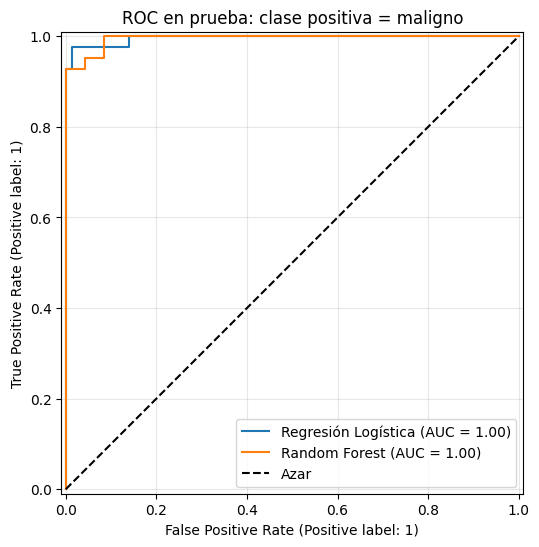

Runs: local_run local_run
Archivos generados: ['Actividad5_resultados/dataset_raw.csv', 'Actividad5_resultados/CHANGELOG.md', 'Actividad5_resultados/diccionario_datos.txt', 'Actividad5_resultados/dataset_cleaned.csv', 'Actividad5_resultados/comparacion_roc.png', 'Actividad5_resultados/dependencias.json', 'Actividad5_resultados/comparacion_metricas.csv', 'Actividad5_resultados/eda.png']
Base de datos MLflow: /content/mlflow.db
Tracking URI: sqlite:////content/mlflow.db
Run Regresión Logística: local_run
Run Random Forest: local_run
Nota: resultados para fines educativos.


In [ ]:
######################################################  Comparación de Curvas ROC  ######################################################

fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_estimator(best_lr, X_test, y_test, ax=ax, name='Regresión Logística')
RocCurveDisplay.from_estimator(best_rf, X_test, y_test, ax=ax, name='Random Forest')

ax.plot([0,1],[0,1],'k--', label='Azar')
ax.set_title('ROC en prueba: clase positiva = maligno');
ax.grid(alpha=.3);ax.legend()
fig.savefig(OUT/'comparacion_roc.png',dpi=160,bbox_inches='tight');
plt.show()
print('Runs:',run_lr,run_rf)
print('Archivos generados:',[str(x) for x in OUT.iterdir()])
print("Base de datos MLflow:", TRACKING_DB)
print("Tracking URI:", mlflow.get_tracking_uri())
print("Run Regresión Logística:", run_lr)
print("Run Random Forest:", run_rf)
print('Nota: resultados para fines educativos.')


In [ ]:
#########################################################  Evidencias de MLflow  ########################################################

import mlflow
import pandas as pd
import json
import shutil
from pathlib import Path
from IPython.display import display
from mlflow.tracking import MlflowClient

# Carpeta de evidencias
EVIDENCIAS = OUT / "evidencias_mlflow"
EVIDENCIAS.mkdir(parents=True, exist_ok=True)

cliente = MlflowClient()

# Recuperar los identificadores desde MLflow
runs = mlflow.search_runs(
    search_all_experiments=True,
    order_by=["start_time DESC"]
)

# Seleccionar las ejecuciones finalizadas
runs_validos = runs[
    runs["status"] == "FINISHED"
]

# Identificar los dos modelos
ids = {}

for modelo in [
    "Regresion_Logistica",
    "Random_Forest"
]:

    seleccion = runs_validos[
        runs_validos["tags.mlflow.runName"] == modelo
    ]

    if seleccion.empty:
        raise ValueError(
            f"No se encontró el modelo {modelo} en MLflow"
        )

    ids[modelo] = seleccion.iloc[0]["run_id"]

print("Modelos recuperados correctamente:")

for modelo, run_id in ids.items():
    print(f"{modelo}: {run_id}")

resumen = []
parametros = []
artefactos = []
trazabilidad = []

for nombre, run_id in ids.items():

    run = cliente.get_run(run_id)

    # 1. Métricas
    resumen.append({
        "Modelo": nombre,
        "Run_ID": run_id,
        "Estado": run.info.status,
        **run.data.metrics
    })

    # 2. Parámetros
    parametros.append({
        "Modelo": nombre,
        "Run_ID": run_id,
        **run.data.params
    })

    # 3. Artefactos
    def listar_artefactos(ruta=""):
        for item in cliente.list_artifacts(run_id, ruta):
            artefactos.append({
                "Modelo": nombre,
                "Run_ID": run_id,
                "Artefacto": item.path,
                "Tipo": "Carpeta" if item.is_dir else "Archivo"
            })

            if item.is_dir:
                listar_artefactos(item.path)

    listar_artefactos()

    # 4. Trazabilidad
    trazabilidad.append({
        "Modelo": nombre,
        "Run_ID": run_id,
        "Experiment_ID": run.info.experiment_id,
        "Estado": run.info.status,
        "Inicio": run.info.start_time,
        "Fin": run.info.end_time,
        "Dataset_SHA256": run.data.tags.get("dataset_sha256"),
        "Semilla": run.data.params.get("seed"),
        "Modelo_URI": run.data.tags.get("modelo_registrado_uri")
    })

# Crear DataFrames
df_metricas = pd.DataFrame(resumen)
df_parametros = pd.DataFrame(parametros)
df_artefactos = pd.DataFrame(artefactos)
df_trazabilidad = pd.DataFrame(trazabilidad)

# Guardar evidencias
df_metricas.to_csv(
    EVIDENCIAS / "01_metricas.csv", index=False
)

df_parametros.to_csv(
    EVIDENCIAS / "02_parametros.csv", index=False
)

df_artefactos.to_csv(
    EVIDENCIAS / "03_artefactos.csv", index=False
)

df_trazabilidad.to_csv(
    EVIDENCIAS / "04_trazabilidad.csv", index=False
)

# Mostrar resultados
print("EVIDENCIA 1: MÉTRICAS")
display(df_metricas)

print("\nEVIDENCIA 2: PARÁMETROS")
display(df_parametros)

print("\nEVIDENCIA 3: ARTEFACTOS")
display(df_artefactos)

print("\nEVIDENCIA 4: TRAZABILIDAD")
display(df_trazabilidad)

# Verificar cumplimiento
metricas_requeridas = {
    "accuracy", "precision", "recall", "f1", "roc_auc"
}

verificaciones = {}

for nombre, run_id in ids.items():
    run = cliente.get_run(run_id)

    uri = run.data.tags.get("modelo_registrado_uri")

    verificaciones[nombre] = {
        "Ejecucion_finalizada": run.info.status == "FINISHED",
        "Metricas_completas": metricas_requeridas.issubset(
            run.data.metrics.keys()
        ),
        "Parametros_registrados": bool(run.data.params),
        "Modelo_identificado": bool(uri),
        "Dataset_identificado": bool(
            run.data.tags.get("dataset_sha256")
        ),
        "Artefactos_registrados": any(
            a["Run_ID"] == run_id
            for a in artefactos
        )
    }

# Guardar verificación
with open(
    EVIDENCIAS / "05_verificacion.json",
    "w",
    encoding="utf-8"
) as archivo:
    json.dump(
        verificaciones,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("\nRESULTADO DE VERIFICACIÓN")
for modelo, pruebas in verificaciones.items():
    print("\n", modelo)
    for criterio, cumple in pruebas.items():
        print(
            "OK" if cumple else "PENDIENTE",
            criterio
        )

# Crear archivo ZIP
archivo_zip = shutil.make_archive(
    str(OUT / "Evidencias_MLflow_Actividad5"),
    "zip",
    root_dir=EVIDENCIAS
)

print("\nEvidencias generadas:", archivo_zip)

Modelos recuperados correctamente:
Regresion_Logistica: 22eb1a87a0724bc3ac887e56e7bb7e45
Random_Forest: 24e8386ebf8243668d2c39f9800b1532
EVIDENCIA 1: MÉTRICAS


,Modelo,Run_ID,Estado,accuracy,precision,recall,f1,roc_auc,best_cv_f1,cv_f1_mean_post_selection
0,Regresion_Logistica,22eb1a87a0724bc3ac887e56e7bb7e45,FINISHED,0.964912,0.975,0.928571,0.951220,0.996032,0.964048,0.964048
1,Random_Forest,24e8386ebf8243668d2c39f9800b1532,FINISHED,0.973684,1.000,0.928571,0.962963,0.995040,0.955285,0.955285



EVIDENCIA 2: PARÁMETROS


,Modelo,Run_ID,seed,cv_folds,test_size,optimization_metric,classifier__C,classifier__penalty,classifier__solver,classifier__max_depth,classifier__min_samples_split,classifier__n_estimators
0,Regresion_Logistica,22eb1a87a0724bc3ac887e56e7bb7e45,42,5,0.2,f1,1.0,l2,lbfgs,NaN,NaN,NaN
1,Random_Forest,24e8386ebf8243668d2c39f9800b1532,42,5,0.2,f1,NaN,NaN,NaN,5,2,100



EVIDENCIA 3: ARTEFACTOS


,Modelo,Run_ID,Artefacto,Tipo
0,Regresion_Logistica,22eb1a87a0724bc3ac887e56e7bb7e45,CHANGELOG.md,Archivo
1,Regresion_Logistica,22eb1a87a0724bc3ac887e56e7bb7e45,confusion.png,Archivo
2,Regresion_Logistica,22eb1a87a0724bc3ac887e56e7bb7e45,cv_scores.json,Archivo
3,Regresion_Logistica,22eb1a87a0724bc3ac887e56e7bb7e45,dataset_sha256.txt,Archivo
4,Regresion_Logistica,22eb1a87a0724bc3ac887e56e7bb7e45,dependencias.json,Archivo
5,Regresion_Logistica,22eb1a87a0724bc3ac887e56e7bb7e45,eda.png,Archivo
6,Regresion_Logistica,22eb1a87a0724bc3ac887e56e7bb7e45,roc.png,Archivo
7,Random_Forest,24e8386ebf8243668d2c39f9800b1532,CHANGELOG.md,Archivo
8,Random_Forest,24e8386ebf8243668d2c39f9800b1532,confusion.png,Archivo
9,Random_Forest,24e8386ebf8243668d2c39f9800b1532,cv_scores.json,Archivo



EVIDENCIA 4: TRAZABILIDAD


,Modelo,Run_ID,Experiment_ID,Estado,Inicio,Fin,Dataset_SHA256,Semilla,Modelo_URI
0,Regresion_Logistica,22eb1a87a0724bc3ac887e56e7bb7e45,1,FINISHED,1792134901278,1792134916474,349e0b6355d9acc2cc25d910999fb906288861f9fb19af...,42,models:/m-7b5299b2ee734362adabf6febaa31990
1,Random_Forest,24e8386ebf8243668d2c39f9800b1532,1,FINISHED,1792134918642,1792134958346,349e0b6355d9acc2cc25d910999fb906288861f9fb19af...,42,models:/m-e895092d89c24010bdf5acf30e3a357d



RESULTADO DE VERIFICACIÓN

 Regresion_Logistica
OK Ejecucion_finalizada
OK Metricas_completas
OK Parametros_registrados
OK Modelo_identificado
OK Dataset_identificado
OK Artefactos_registrados

 Random_Forest
OK Ejecucion_finalizada
OK Metricas_completas
OK Parametros_registrados
OK Modelo_identificado
OK Dataset_identificado
OK Artefactos_registrados

Evidencias generadas: /content/Actividad5_resultados/Evidencias_MLflow_Actividad5.zip
